In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_o = pd.read_csv('orders_clean.csv')

In [3]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       29951 non-null  str    
 1   customer_id    29065 non-null  str    
 2   order_date     29951 non-null  str    
 3   product_id     29951 non-null  str    
 4   seller_id      29951 non-null  str    
 5   quantity       29951 non-null  int64  
 6   list_price     29951 non-null  float64
 7   discount_pct   29951 non-null  int64  
 8   sales_amount   29951 non-null  float64
 9   cost_amount    29951 non-null  float64
 10  profit         29951 non-null  float64
 11  order_status   29951 non-null  str    
 12  shipping_days  29951 non-null  float64
dtypes: float64(5), int64(2), str(6)
memory usage: 4.2 MB


In [4]:
df_o['order_date'] = pd.to_datetime(df_o['order_date'])

In [6]:
df_o['shipping_days'] = df_o['shipping_days'].astype(int)

In [7]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       29951 non-null  str           
 1   customer_id    29065 non-null  str           
 2   order_date     29951 non-null  datetime64[us]
 3   product_id     29951 non-null  str           
 4   seller_id      29951 non-null  str           
 5   quantity       29951 non-null  int64         
 6   list_price     29951 non-null  float64       
 7   discount_pct   29951 non-null  int64         
 8   sales_amount   29951 non-null  float64       
 9   cost_amount    29951 non-null  float64       
 10  profit         29951 non-null  float64       
 11  order_status   29951 non-null  str           
 12  shipping_days  29951 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(3), str(5)
memory usage: 3.9 MB


### 1. Monthly sales table

In [9]:
df = df_o[df_o['order_status'] != 'Cancelled']

In [10]:
df.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6
3,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9
4,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4
5,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2


In [11]:
df['Year'] = df['order_date'].dt.year

In [12]:
df['Month'] = df['order_date'].dt.month

In [13]:
df.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days,Year,Month
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5,2023,11
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6,2024,8
3,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9,2023,11
4,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4,2024,8
5,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2,2023,7


In [27]:
monthly = df.groupby(['Year','Month']).agg(Revenue = ('sales_amount', 'sum'), Orders = ('order_id', 'count')).reset_index()

In [28]:
monthly

,Year,Month,Revenue,Orders
0,2022,1,50030.10,15
1,2022,2,248133.76,30
2,2022,3,376629.45,44
3,2022,4,286961.46,58
4,2022,5,548661.18,111
5,2022,6,545805.10,133
6,2022,7,924938.70,158
7,2022,8,912158.45,211
8,2022,9,1037912.49,252
9,2022,10,1388728.83,285


In [29]:
monthly['revenue_m'] = monthly['Revenue'] / 1e6

In [30]:
monthly.dtypes

Year           int32
Month          int32
Revenue      float64
Orders         int64
revenue_m    float64
dtype: object

In [31]:
# first day of each month
monthly['date'] = pd.to_datetime(monthly[['Year', 'Month']].assign(day=1))

In [32]:
monthly.head()

,Year,Month,Revenue,Orders,revenue_m,date
0,2022,1,50030.10,15,0.050030,2022-01-01
1,2022,2,248133.76,30,0.248134,2022-02-01
2,2022,3,376629.45,44,0.376629,2022-03-01
3,2022,4,286961.46,58,0.286961,2022-04-01
4,2022,5,548661.18,111,0.548661,2022-05-01


### 3. Finding which months are busy

In [33]:
monthly['index'] = monthly['Revenue'] / monthly.groupby('Year')['Revenue'].transform('mean')

In [35]:
# average index per calendar month:
season = monthly.groupby('Month')['index'].mean().reset_index()

In [36]:
season['month_name'] = pd.to_datetime(season['Month'], format='%m').dt.strftime('%b')

In [37]:
season['status'] = season['index'].apply(lambda x: 'Peak' if x >= 1.2 else ('Slow' if x <= 0.8 else 'Normal'))

In [39]:
season

,Month,index,month_name,status
0,1,0.368360,Jan,Slow
1,2,0.431347,Feb,Slow
2,3,0.536169,Mar,Slow
3,4,0.586941,Apr,Slow
4,5,0.708240,May,Slow
5,6,0.760475,Jun,Slow
6,7,0.900149,Jul,Normal
7,8,0.889607,Aug,Normal
8,9,0.998068,Sep,Normal
9,10,1.240625,Oct,Peak


## VISUALIZATION

### 1. Monthly revenue over time

In [64]:
monthly.tail()

,Year,Month,Revenue,Orders,revenue_m,date,index
31,2024,8,3778224.92,873,3.778225,2024-08-01,0.467368
32,2024,9,4680750.26,802,4.680750,2024-09-01,0.579011
33,2024,10,4672219.61,861,4.672220,2024-10-01,0.577955
34,2024,11,3436184.73,740,3.436185,2024-11-01,0.425057
35,2024,12,52881953.64,10444,52.881954,2024-12-01,6.541517


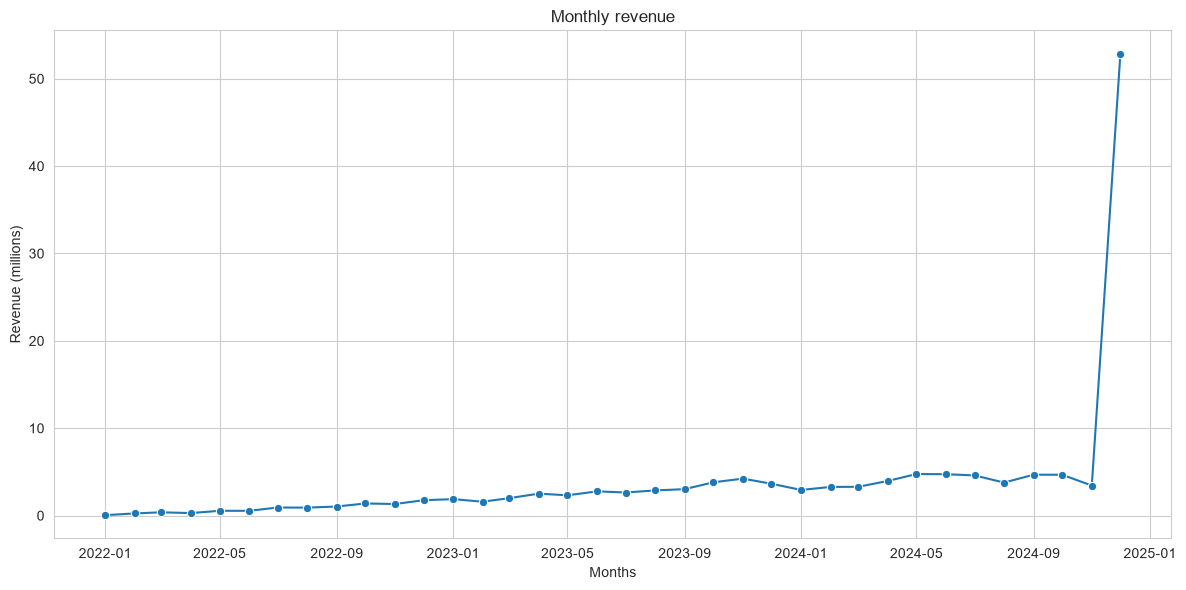

In [63]:
sns.set_style('whitegrid')
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly, x = 'date', y='revenue_m', marker='o')
plt.xlabel('Months')
plt.ylabel('Revenue (millions)')
plt.title('Monthly revenue')
plt.tight_layout()
plt.show()

### 2. Seasonality index by month

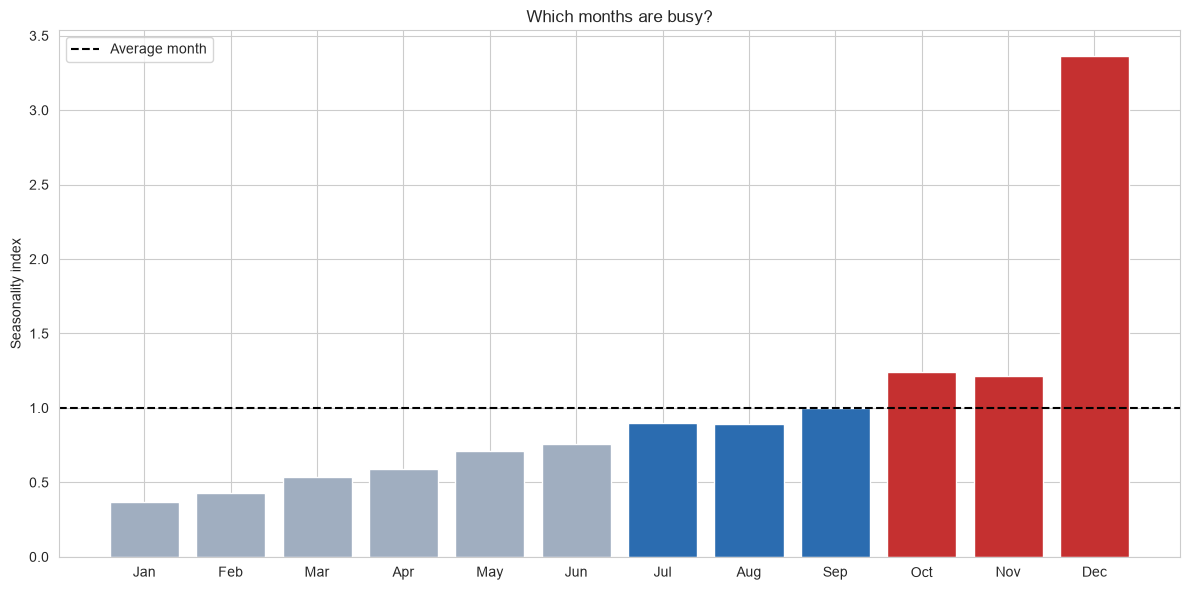

In [66]:
colors = season['status'].map({'Peak': '#c53030', 'Slow': '#a0aec0', 'Normal': '#2b6cb0'})

plt.figure(figsize=(12, 6))
plt.bar(season['month_name'], season['index'], color=list(colors))
plt.axhline(1, color='black', linestyle='--', label='Average month')
plt.ylabel('Seasonality index')
plt.title('Which months are busy?')
plt.legend()
plt.tight_layout()
plt.show()

### 3. Revenue by year and month

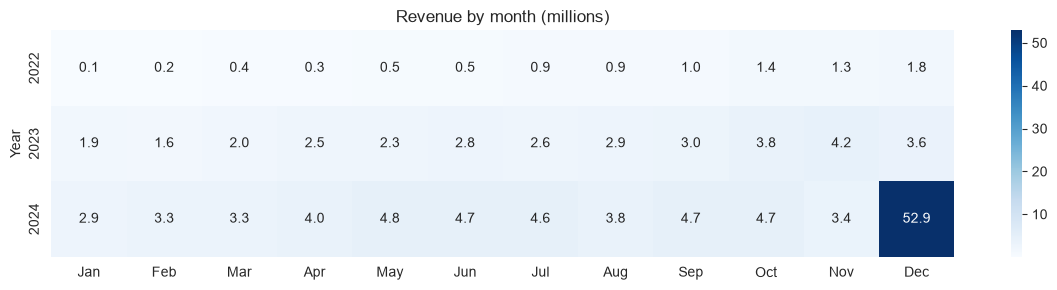

In [69]:
heat = monthly.pivot(index='Year', columns='Month', values='revenue_m')
heat.columns = season['month_name']

plt.figure(figsize=(12, 3))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='Blues')
plt.xlabel('')
plt.title('Revenue by month (millions)')
plt.tight_layout()
plt.show()